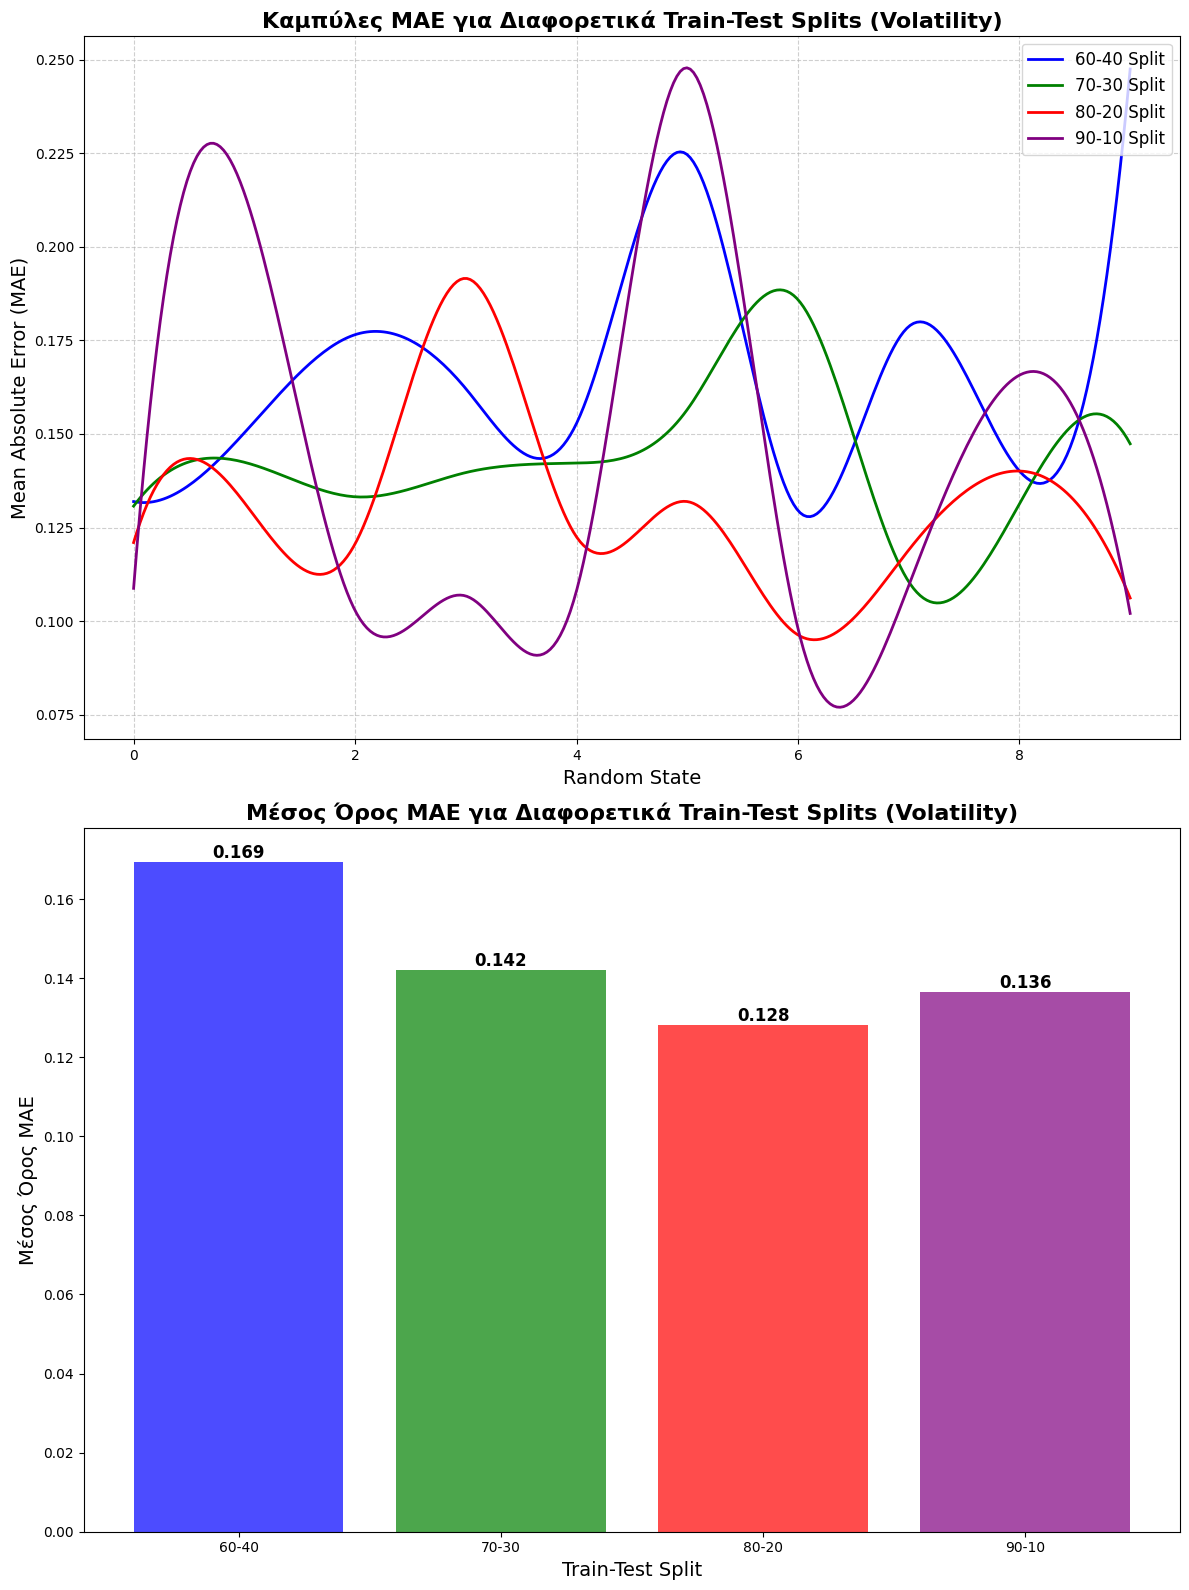

In [1]:

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# Δεδομένα για τα splits
random_states = np.array(list(range(10)))

mae_60_40 =np.array([
    0.13195406550915895, 0.15030210840229413, 0.1765159014436183,
    0.1621148858181533, 0.15282560385121288, 0.22459055903459624,
    0.12956348662301936, 0.17869309633661284, 0.1401163857348629,
    0.24746019981443945
])
mae_70_30 = np.array([
    0.1307410537826255, 0.1424499351083529, 0.13322434386423107,
    0.13969829426941652, 0.1422322491866835, 0.1565216464529542,
    0.1858687407607343, 0.11055359886734678, 0.1313446226556299,
    0.1473800784622214
])
mae_80_20 = np.array([
    0.12101153129761062, 0.13167474593106113, 0.12065173684335717,
    0.19155798389311593, 0.1225166637400067, 0.13195503420964874,
    0.09634068071857686, 0.1190224706564437, 0.1401036804130325,
    0.1061995269932947
])
mae_90_10 = np.array([
    0.10878183956148466, 0.214340868585746, 0.10287365629781342,
    0.10674023356910982, 0.10814415840100303, 0.24777358773370223,
    0.09805661947868577, 0.10949816361033886, 0.16570959394356125,
    0.10207883579659383
])

# Υπολογισμός μέσου όρου για κάθε split
mean_mae = [
    mae_60_40.mean(),
    mae_70_30.mean(),
    mae_80_20.mean(),
    mae_90_10.mean()
]

splits = ["60-40", "70-30", "80-20", "90-10"]

# Δημιουργία λείων καμπυλών με Spline Interpolation
x_smooth = np.linspace(random_states.min(), random_states.max(), 300)

mae_60_40_smooth = make_interp_spline(random_states, mae_60_40)(x_smooth)
mae_70_30_smooth = make_interp_spline(random_states, mae_70_30)(x_smooth)
mae_80_20_smooth = make_interp_spline(random_states, mae_80_20)(x_smooth)
mae_90_10_smooth = make_interp_spline(random_states, mae_90_10)(x_smooth)

# Δημιουργία γραφικής παράστασης
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# Πρώτο γράφημα: Καμπύλες MAE
axes[0].plot(x_smooth, mae_60_40_smooth, color='blue', label='60-40 Split', linewidth=2)
axes[0].plot(x_smooth, mae_70_30_smooth, color='green', label='70-30 Split', linewidth=2)
axes[0].plot(x_smooth, mae_80_20_smooth, color='red', label='80-20 Split', linewidth=2)
axes[0].plot(x_smooth, mae_90_10_smooth, color='purple', label='90-10 Split', linewidth=2)


axes[0].set_title('Καμπύλες MAE για Διαφορετικά Train-Test Splits (Volatility)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Random State', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12, loc='upper right')

# Δεύτερο γράφημα: Bar Chart Μέσων Όρων MAE
bars = axes[1].bar(splits, mean_mae, color=['blue', 'green', 'red', 'purple'], alpha=0.7)

axes[1].set_title('Μέσος Όρος MAE για Διαφορετικά Train-Test Splits (Volatility)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Train-Test Split', fontsize=14)
axes[1].set_ylabel('Μέσος Όρος MAE', fontsize=14)

# Προσθήκη τιμών πάνω από τις μπάρες
for bar, value in zip(bars, mean_mae):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()
